# V3 boom flight, 17 Oct 2026, McAuley Park

This morning's flight (`hardware/flight_logs/2026-10-17_mcauley_park_v3_boom.bin`),
with the longer boom and **raw CAN logging switched on**, compared with last
night's V2 flight on the same pitch.

What was flown, all found from the log itself:

* **yaw spins** in Loiter at ~3 m (the calibration manoeuvre)
* the **Auto mission**: calibration box, then the crosshatch survey at 10 m
  (6 min, ended with the RTL switch)
* two **Loiter** segments at 2-5 m, and motors-off time on the ground between

**Headlines** (from this run; section 7 recomputes them live)

| | Today (V3 boom, raw CAN) | Last night (V2 boom, MAG log) |
|---|---|---|
| **Logging** | **25 Hz, ~12-24 nT steps** - raw CAN logging works | 10 Hz, 100 nT steps |
| **Sensor noise, motors off** | **±11-13 nT** - at the RM3100's own 15 nT spec | ±23-35 nT (rounding) |
| **Calibrated, in flight** | **±22 nT** (node 125), **±24 nT** (node 124) | ±36 / ±64 nT |
| **Fast noise in flight (> 0.5 Hz)** | **15 nT** both - the drone is no longer the limit | 32 / 41 nT |
| **Calibrate, then fly** | 26 s of yaw spins at 3 m calibrates the 10 m survey to **±31 / ±40 nT**; the 18 s box to ±34 / ±39 nT | box only: ±43 / ±120 nT |
| **When the motors arm** | RM3100s move **≤6 nT**; GPS puck still jumps +1.2-1.5 uT | RM3100s up to 84 nT |
| **Ground signal here** | none: crossing lines r = -0.18, so nothing above ~15 nT at 10 m | none above ~18 nT |

Node 124's jump (64 -> 24 nT) mixes three things - the longer boom, the raw
CAN resolution, and bypassing a bad ArduPilot scale factor (1.085) on that
compass - and this flight cannot separate them without the new distances.

## 0. Setup

In [1]:
import datetime as dt, math, pathlib, urllib.request
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from matplotlib.colors import LinearSegmentedColormap
from scipy.interpolate import griddata
from scipy.ndimage import median_filter
from scipy.signal import detrend
from sensor import FieldModel

REPO = pathlib.Path("../..").resolve()   # run from modelling/notebooks
LOG = REPO / "hardware/flight_logs/2026-10-17_mcauley_park_v3_boom.bin"
LAST_NIGHT = REPO / "hardware/flight_logs/2026-10-16_mcauley_park_v2_boom.bin"
CACHE = REPO / "modelling/data/ardupilot"
TILES = REPO / "modelling/data/tiles"
DATE = dt.date(2026, 10, 17)
QFLOOR_NT = 100 / math.sqrt(12)     # the MAG log's 1 mG rounding, ~29 nT

SENSORS = {   # the CAN streams are the full-resolution ones; MAG0 has no CAN stream
    "puck":  dict(label="GPS puck (IST8310, MAG log)", colour="#1baf7a"),
    "n124":  dict(label="RM3100 node 124 (MAG1), raw CAN", colour="#eb6834"),
    "n125":  dict(label="RM3100 node 125 (MAG2), raw CAN", colour="#2a78d6"),
}
INK, INK2, MUTED, GRID = "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
DIVERGING = LinearSegmentedColormap.from_list(
    "bluered", ["#104281", "#2a78d6", "#86b6ef", "#f0efec", "#f2a3a2", "#e34948", "#8f2423"])
plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
                     "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK2, "xtick.color": MUTED,
                     "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 9,
                     "axes.titlesize": 10, "axes.titlelocation": "left", "legend.frameon": False})

## 1. Read the log, including the raw CAN frames

`CAN_P1_OPTIONS` / `CAN_P2_OPTIONS` = 1 (LogAllFrames) puts every CAN frame
in the log as `CANF`. The RM3100 nodes send DroneCAN `MagneticFieldStrength`
(type 1001): three 16-bit floats in gauss. Decoded here at full resolution.

In [2]:
def read(path):
    cache = CACHE / (path.stem + ".npz")
    z = np.load(cache, allow_pickle=True)
    return {k: z[k] for k in z.files} | {"parm": z["parm"].item()}

D = read(LOG)
P = D["parm"]
print("CAN_P1_OPTIONS", P["CAN_P1_OPTIONS"], "CAN_P2_OPTIONS", P["CAN_P2_OPTIONS"],
      "| WP_YAW_BEHAVIOR", P["WP_YAW_BEHAVIOR"])
C = D["CANMAG"]
for node in (124, 125):
    s = C[C[:, 1] == node]; d = np.abs(np.diff(s[:, 2:5], axis=0))
    print(f"node {node}: {len(s)} CAN readings at {len(s) / np.ptp(s[:, 0]):.1f} Hz, "
          f"median step between readings {np.median(d[d > 0]):.1f} nT, smallest {d[d > 0].min():.1f} nT")
for i in (1, 2):
    m = D["MAG"][D["MAG"][:, 1] == i]; d = np.abs(np.diff(m[:, 2:5] * 100, axis=0))
    print(f"MAG{i} (the usual log): {len(m) / np.ptp(m[:, 0]):.1f} Hz, smallest step {d[d > 0].min():.0f} nT")

CAN_P1_OPTIONS 1.0 CAN_P2_OPTIONS 1.0 | WP_YAW_BEHAVIOR 2.0
node 124: 19988 CAN readings at 24.9 Hz, median step between readings 62.3 nT, smallest 0.8 nT
node 125: 19993 CAN readings at 24.9 Hz, median step between readings 62.2 nT, smallest 0.8 nT
MAG1 (the usual log): 9.9 Hz, smallest step 100 nT
MAG2 (the usual log): 9.9 Hz, smallest step 100 nT


## 2. Phases

In [3]:
GPS = D["GPS"][D["GPS"][:, 1] >= 3]
LAT0, LON0 = GPS[:, 2].mean(), GPS[:, 3].mean()
M_LAT, M_LON = 111_320.0, 111_320.0 * math.cos(math.radians(LAT0))
F0 = float(np.linalg.norm(FieldModel(date=DATE).core_field_ned(LAT0, LON0, 60.0)))
msgs = list(zip(D["msg_t"], D["msg_s"]))
MODE, ARM, ATT, CT = D["MODE"], D["ARM"], D["ATT"], D["CTUN"]
auto = MODE[MODE[:, 1] == 3, 0][0]; auto_end = MODE[(MODE[:, 0] > auto) & (MODE[:, 1] != 3), 0][0]
box0 = next(t for t, s in msgs if s == "Mission: 2 WP"); surv0 = next(t for t, s in msgs if s == "Mission: 6 WP")
yaw_u = np.degrees(np.unwrap(np.radians(ATT[:, 3]))); yr = np.abs(np.gradient(yaw_u, ATT[:, 0]))
spin = ATT[(ATT[:, 0] < auto) & (yr > 20), 0]                 # fast yaw before the mission
arm_on, arm_off = ARM[ARM[:, 1] == 1, 0], ARM[ARM[:, 1] == 0, 0]
PHASES = {"spins": (spin.min() - 3, spin.max() + 3), "box": (box0 + 2, surv0),
          "survey": (surv0 + 1, auto_end - 1)}
GROUND = [(a + 1, b - 1) for a, b in zip(arm_off, list(arm_on[arm_on > arm_off[0]]) + [D["MAG"][-1, 0]]) if b - a > 6]
for k, (a, b) in PHASES.items():
    print(f"{k:7s} {a:6.1f} - {b:6.1f} s ({b - a:4.0f} s)")
print("motors off, on the ground:", [(round(a), round(b)) for a, b in GROUND])
print(f"IGRF total field {F0:.0f} nT")

def stream(name):
    if name == "puck":
        m = D["MAG"][D["MAG"][:, 1] == 0]; t, v = m[:, 0], m[:, 2:5] * 100
    else:
        s = C[C[:, 1] == int(name[1:])]; t, v = s[:, 0], s[:, 2:5]
    o = dict(t=t, v=v, B=np.linalg.norm(v, axis=1)); o["u"] = v / o["B"][:, None]
    o["e"] = (np.interp(t, GPS[:, 0], GPS[:, 3]) - LON0) * M_LON
    o["n"] = (np.interp(t, GPS[:, 0], GPS[:, 2]) - LAT0) * M_LAT
    o["I"] = np.interp(t, D["BAT"][:, 0], D["BAT"][:, 2])
    esc = D["ESC"]
    o["rpm"] = np.column_stack([np.interp(t, esc[esc[:, 1] == k, 0], esc[esc[:, 1] == k, 2]) for k in np.unique(esc[:, 1])]) / 1000
    o["yaw"] = np.interp(t, ATT[:, 0], yaw_u) % 360
    o["alt"] = np.interp(t, CT[:, 0], CT[:, 2])
    o["yawrate"] = np.interp(t, ATT[:, 0], yr)
    o["straight"] = median_filter((o["yawrate"] < 8).astype(float), size=11) > 0.5
    return o

FS = {k: stream(k) for k in SENSORS}
inp = lambda o, k: (o["t"] > PHASES[k][0]) & (o["t"] < PHASES[k][1])
H = np.median(CT[(CT[:, 0] > PHASES["survey"][0]) & (CT[:, 0] < PHASES["survey"][1]), 2])
for o in FS.values():
    o["steady"] = np.abs(o["alt"] - H) < 1.0

spins    141.7 -  168.1 s (  26 s)
box      237.5 -  255.7 s (  18 s)
survey   256.7 -  589.4 s ( 333 s)
motors off, on the ground: [(206, 223), (641, 646), (752, 764), (884, 897)]
IGRF total field 49493 nT


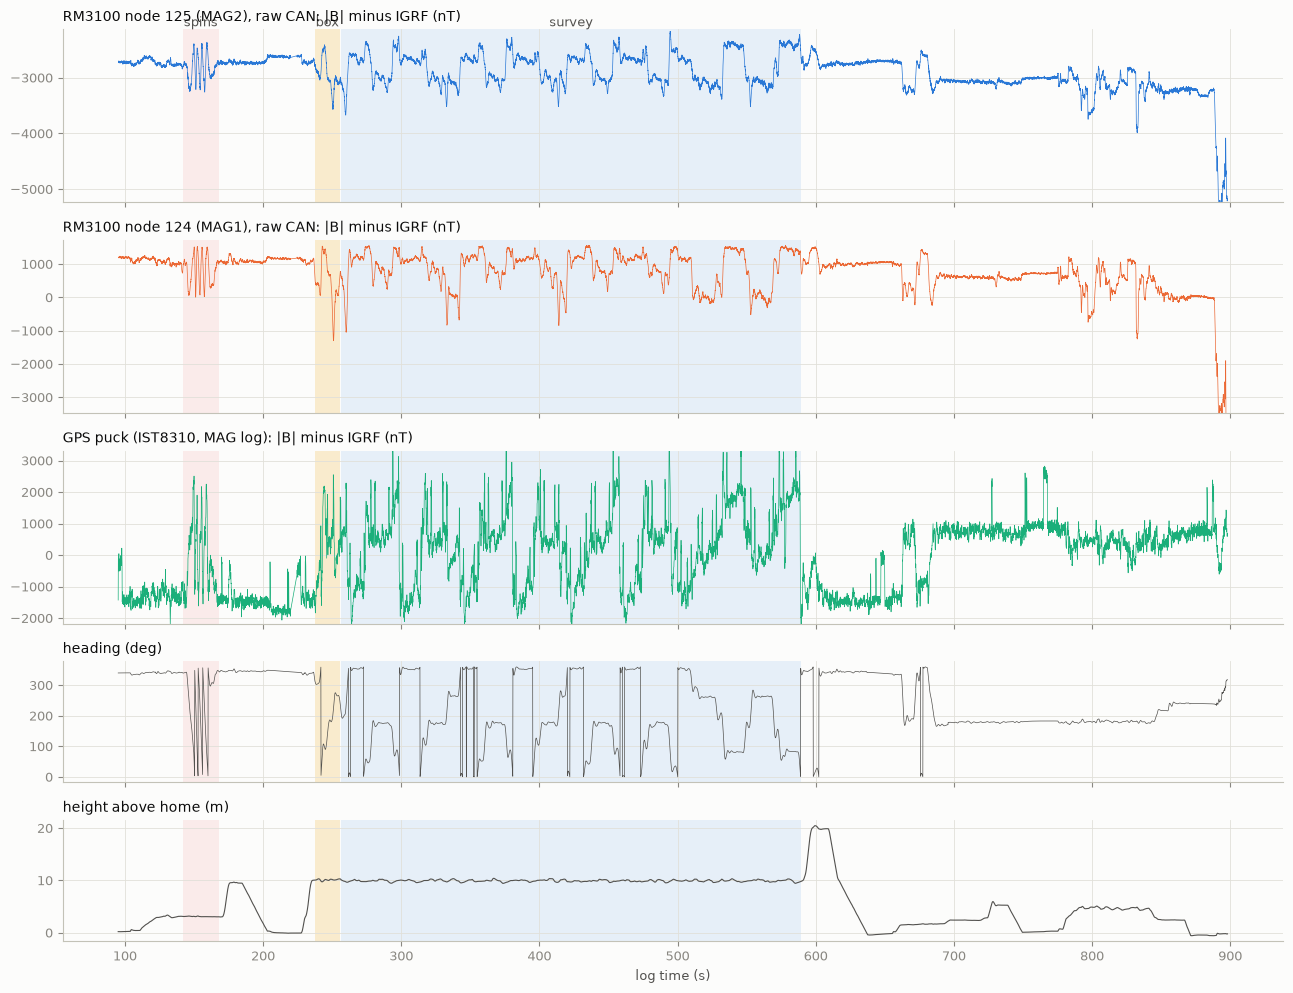

In [4]:
fig, ax = plt.subplots(5, 1, figsize=(13, 10), sharex=True, gridspec_kw=dict(height_ratios=[1, 1, 1, .7, .7]))
for a, k in zip(ax[:3], ("n125", "n124", "puck")):
    o = FS[k]; a.plot(o["t"], o["B"] - F0, color=SENSORS[k]["colour"], lw=0.5)
    lo, hi = np.percentile(o["B"] - F0, [0.5, 99.5]); a.set_ylim(lo - 200, hi + 200)
    a.set_title(f"{SENSORS[k]['label']}: |B| minus IGRF (nT)", color=INK)
ax[3].plot(ATT[:, 0], ATT[:, 3], color=INK2, lw=0.5); ax[3].set_title("heading (deg)", color=INK)
ax[4].plot(CT[:, 0], CT[:, 2], color=INK2, lw=0.8); ax[4].set_title("height above home (m)", color=INK)
for a in ax:
    for k, (t0, t1) in PHASES.items():
        a.axvspan(t0, t1, color={"spins": "#f2a3a2", "box": "#eda100", "survey": "#86b6ef"}[k], alpha=0.18, lw=0)
for k, (t0, t1) in PHASES.items():
    ax[0].text((t0 + t1) / 2, ax[0].get_ylim()[1], k, ha="center", va="bottom", color=INK2)
ax[-1].set_xlabel("log time (s)"); fig.tight_layout()

## 3. Calibration: does a calibration from the spins hold for the survey?

Same Tolles-Lawson model as last night: each sensor's |B| error from the
direction of the field in its own axes (permanent + induced), plus current
and the four motor speeds. Scored only on data it was not fitted on:

* **spins -> survey**: fitted on the yaw spins at 3 m only, applied to the
  10 m survey. This is the operational recipe: calibrate, then fly.
* **box -> survey**: fitted on the 20 s mission box only.
* **survey, 2-fold**: survey split into alternating 60 s blocks; each half
  fitted on the other.

In [5]:
def design(o, sel, motors=True):
    x, y, z = o["u"][sel].T
    cols = [np.ones_like(x), x, y, z, x * x, y * y, x * y, x * z, y * z]
    if motors: cols += [o["I"][sel]] + list(o["rpm"][sel].T)
    return np.column_stack(cols)

def fit(o, sel, lam=1e-3, motors=True):
    X = design(o, sel, motors); y = o["B"][sel] - F0
    mu, sd = X.mean(0), X.std(0); mu[0], sd[0] = 0.0, 1.0
    Z = (X - mu) / sd
    beta = np.linalg.solve(Z.T @ Z + lam * len(Z) * np.diag(np.r_[0.0, np.ones(Z.shape[1] - 1)]), Z.T @ y)
    return lambda oo, s: ((design(oo, s, motors) - mu) / sd) @ beta

COMP = {}
for k, o in FS.items():
    sv = inp(o, "survey") & o["steady"]
    y = o["B"] - F0
    fold = (((o["t"] - PHASES["survey"][0]) // 60) % 2).astype(int)
    r = np.full(len(y), np.nan)
    for f in (0, 1):
        r[sv & (fold == f)] = y[sv & (fold == f)] - fit(o, sv & (fold != f))(o, sv & (fold == f))
    r -= np.nanmean(r)
    r_spin = y[sv] - fit(o, inp(o, "spins"), lam=1e-2, motors=False)(o, sv)
    r_box = y[sv] - fit(o, inp(o, "box") & o["steady"], lam=1e-2, motors=False)(o, sv)
    hz = 1 / np.median(np.diff(o["t"]))
    ok = np.isfinite(r); fast = r[ok] - median_filter(r[ok], size=int(2 * hz) | 1, mode="nearest")
    COMP[k] = dict(r=r, raw=np.std(y[sv]), cv=np.nanstd(r), fast=fast.std(), spin=np.std(r_spin), box=np.std(r_box), hz=hz)
TABLE = pd.DataFrame({SENSORS[k]["label"]: {
    "raw spread over the survey": c["raw"], "calibrated from the spins only": c["spin"],
    "calibrated from the box only": c["box"], "calibrated, survey 2-fold": c["cv"],
    "  of which faster than 0.5 Hz": c["fast"]} for k, c in COMP.items()}).T
display(TABLE.round(0).astype(int).rename(columns=lambda c: c + " (nT)"))

,raw spread over the survey (nT),calibrated from the spins only (nT),calibrated from the box only (nT),"calibrated, survey 2-fold (nT)",of which faster than 0.5 Hz (nT)
"GPS puck (IST8310, MAG log)",1183,520,474,462,431
"RM3100 node 124 (MAG1), raw CAN",513,40,39,24,15
"RM3100 node 125 (MAG2), raw CAN",278,31,34,22,15


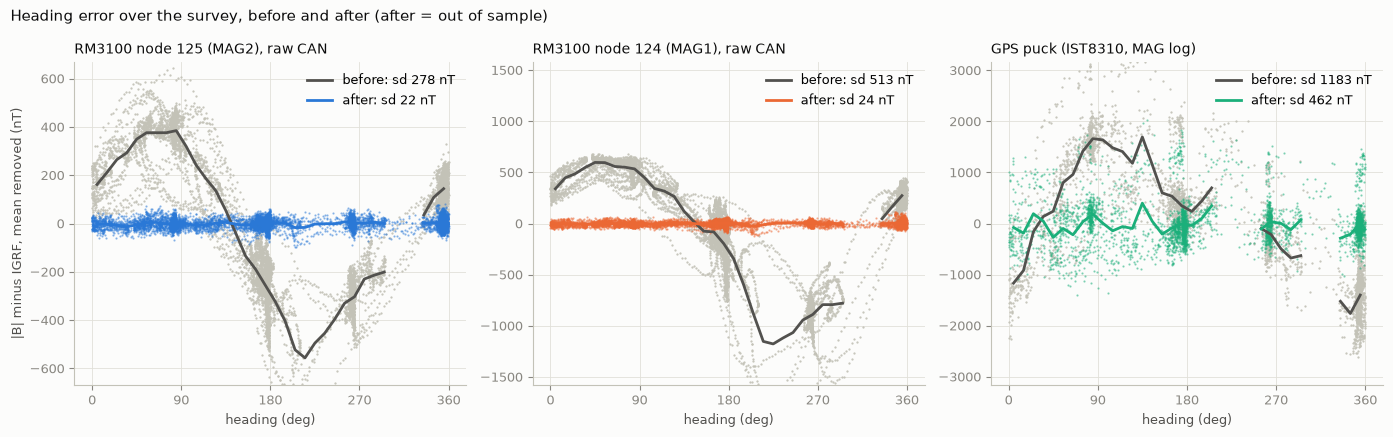

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4.4))
bins = np.arange(0, 361, 10); mid = bins[:-1] + 5
for a, k in zip(ax, ("n125", "n124", "puck")):
    o, c = FS[k], COMP[k]; sel = inp(o, "survey") & o["steady"]
    raw = (o["B"] - F0)[sel]; raw = raw - raw.mean(); comp = c["r"][sel]
    a.plot(o["yaw"][sel], raw, ".", ms=1.2, color="#c3c2b7", rasterized=True)
    a.plot(o["yaw"][sel], comp, ".", ms=1.2, color=SENSORS[k]["colour"], alpha=0.5, rasterized=True)
    for v, col, lab in ((raw, INK2, "before"), (comp, SENSORS[k]["colour"], "after")):
        kk = np.digitize(o["yaw"][sel], bins) - 1
        mean = np.array([np.mean(v[kk == j]) if (kk == j).sum() > 20 else np.nan for j in range(len(mid))])
        a.plot(mid, mean, color=col, lw=2, label=f"{lab}: sd {np.std(v):.0f} nT")
    lim = np.percentile(np.abs(raw), 99) * 1.1; a.set_ylim(-lim, lim)
    a.set_xticks(range(0, 361, 90)); a.set_xlabel("heading (deg)"); a.set_title(SENSORS[k]["label"], color=INK); a.legend(loc="upper right")
ax[0].set_ylabel("|B| minus IGRF, mean removed (nT)")
fig.suptitle("Heading error over the survey, before and after (after = out of sample)", x=0.01, ha="left", color=INK)
fig.tight_layout()

## 4. Interference, in the same format as last night

For each sensor: motors-off noise on the ground, raw and calibrated spread in
flight, the jump when the motors arm, the biggest short spike, and the
peak-to-peak. Last night's numbers (V2 boom, 10 Hz MAG log) alongside.

In [7]:
def interference(o, ground, fly, arms, cal_sd):
    g = [detrend(o["B"][(o["t"] > a) & (o["t"] < b)]).std() for a, b in ground if ((o["t"] > a) & (o["t"] < b)).sum() > 30]
    gm = np.mean(np.concatenate([o["B"][(o["t"] > a) & (o["t"] < b)] for a, b in ground]))
    f = (o["t"] > fly[0]) & (o["t"] < fly[1]) & o["steady"]
    jumps = [o["B"][(o["t"] > a + 0.5) & (o["t"] < a + 3)].mean() - o["B"][(o["t"] > a - 3) & (o["t"] < a - 0.2)].mean() for a in arms]
    hz = 1 / np.median(np.diff(o["t"])); dev = o["B"][f] - median_filter(o["B"][f], size=int(hz) | 1)
    return {"motors off, on the ground (nT)": f"±{np.median(g):.0f}",
            "flying, raw (nT)": f"±{o['B'][f].std():.0f}, {o['B'][f].mean() - gm:+.0f} vs ground",
            "flying, calibrated (nT)": f"±{cal_sd:.0f}",
            "jump when motors arm (nT)": " / ".join(f"{j:+.0f}" for j in jumps if np.isfinite(j)),
            "biggest spike in flight (nT)": f"{np.abs(dev).max():.0f}",
            "peak-to-peak in flight (nT)": f"{np.ptp(o['B'][f]):.0f}"}

arms = [a for a in ARM[ARM[:, 1] == 1, 0] if any(abs(a - b) < 15 for b, _ in GROUND) or True]
TODAY = pd.DataFrame({SENSORS[k]["label"]: interference(FS[k], GROUND, PHASES["survey"], ARM[ARM[:, 1] == 1, 0], COMP[k]["cv"])
                      for k in SENSORS})
LAST = pd.DataFrame({
    "GPS puck (last night)": {"motors off, on the ground (nT)": "±89", "flying, raw (nT)": "±1299, -350 vs ground",
        "flying, calibrated (nT)": "±454", "jump when motors arm (nT)": "+1197 / +1333",
        "biggest spike in flight (nT)": "1938", "peak-to-peak in flight (nT)": "7261"},
    "RM3100 inner, MAG log (last night)": {"motors off, on the ground (nT)": "±23", "flying, raw (nT)": "±885, +1243 vs ground",
        "flying, calibrated (nT)": "±64", "jump when motors arm (nT)": "-21 / +84",
        "biggest spike in flight (nT)": "411", "peak-to-peak in flight (nT)": "5546"},
    "RM3100 outer, MAG log (last night)": {"motors off, on the ground (nT)": "±35", "flying, raw (nT)": "±292, +419 vs ground",
        "flying, calibrated (nT)": "±36", "jump when motors arm (nT)": "-30 / +21",
        "biggest spike in flight (nT)": "153", "peak-to-peak in flight (nT)": "1615"}})
pd.set_option("display.max_colwidth", 60)
display(pd.concat([TODAY, LAST], axis=1).T)

,"motors off, on the ground (nT)","flying, raw (nT)","flying, calibrated (nT)",jump when motors arm (nT),biggest spike in flight (nT),peak-to-peak in flight (nT)
"GPS puck (IST8310, MAG log)",±256,"±1183, +587 vs ground",±462,+1235 / +1529,1281,6359
"RM3100 node 124 (MAG1), raw CAN",±13,"±513, +722 vs ground",±24,+6 / -4,190,2610
"RM3100 node 125 (MAG2), raw CAN",±11,"±278, +399 vs ground",±22,-5 / -6,106,1503
GPS puck (last night),±89,"±1299, -350 vs ground",±454,+1197 / +1333,1938,7261
"RM3100 inner, MAG log (last night)",±23,"±885, +1243 vs ground",±64,-21 / +84,411,5546
"RM3100 outer, MAG log (last night)",±35,"±292, +419 vs ground",±36,-30 / +21,153,1615


## 5. Did raw CAN logging fix the resolution?

The same sensor, the same seconds: the usual `MAG` log (100 nT steps, 10 Hz)
against the raw CAN stream (16-bit floats, 25 Hz).

node 124, motors off, per-axis noise: MAG log [31. 13. 27.] nT, raw CAN [18.4 11.  13.7] nT
node 125, motors off, per-axis noise: MAG log [33. 14. 24.] nT, raw CAN [17.5 10.4 11.7] nT


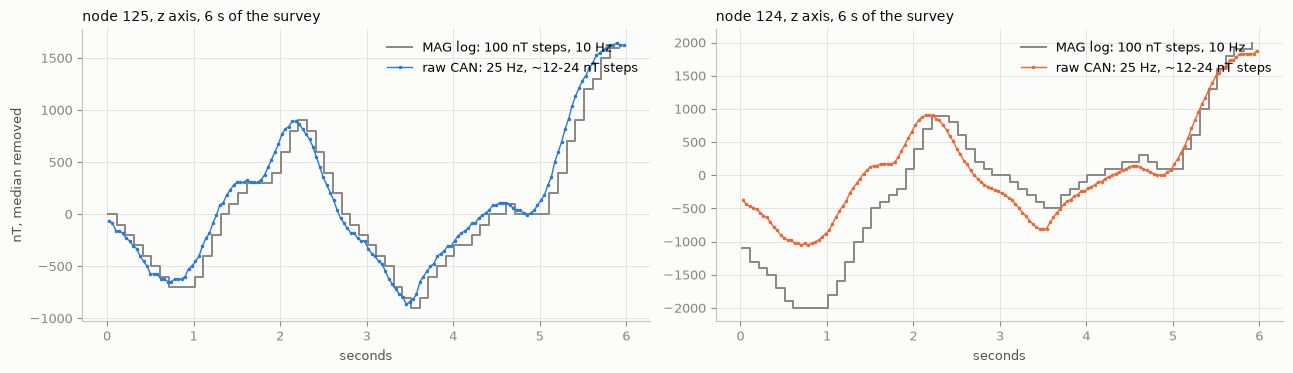

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for a, (i, node) in zip(ax, ((2, 125), (1, 124))):
    m = D["MAG"][D["MAG"][:, 1] == i]; s = C[C[:, 1] == node]
    t0 = PHASES["survey"][0] + 60; w = lambda t: (t > t0) & (t < t0 + 6)
    mz, sz = m[w(m[:, 0]), 4] * 100, s[w(s[:, 0]), 4]
    a.step(m[w(m[:, 0]), 0] - t0, mz - np.median(mz), where="post", color=MUTED, lw=1.4, label="MAG log: 100 nT steps, 10 Hz")
    a.plot(s[w(s[:, 0]), 0] - t0, sz - np.median(sz), ".-", color=SENSORS[f"n{node}"]["colour"], lw=1, ms=3, label="raw CAN: 25 Hz, ~12-24 nT steps")
    a.set_title(f"node {node}, z axis, 6 s of the survey", color=INK); a.set_xlabel("seconds"); a.legend(loc="upper right")
ax[0].set_ylabel("nT, median removed"); fig.tight_layout()
for i, node in ((1, 124), (2, 125)):
    m = D["MAG"][D["MAG"][:, 1] == i]; s = C[C[:, 1] == node]
    gm = [detrend(m[(m[:, 0] > a) & (m[:, 0] < b), 2:5] * 100, axis=0).std(0) for a, b in GROUND]
    gs = [detrend(s[(s[:, 0] > a) & (s[:, 0] < b), 2:5], axis=0).std(0) for a, b in GROUND]
    print(f"node {node}, motors off, per-axis noise: MAG log {np.median(gm, 0).round(0)} nT, raw CAN {np.median(gs, 0).round(1)} nT")

## 6. The map, and is any of it ground?

The outer sensor's 2-fold calibrated residual, straight flight only, gridded at
1 m. The test is the crosshatch: ground crossed by N-S lines and by E-W lines
must agree; the drone's field does not.

RM3100 node 125 (MAG2), raw CAN: N-S vs E-W lines over the same ground: r = -0.18 over 56 cells, per-cell noise 15 nT
RM3100 node 124 (MAG1), raw CAN: N-S vs E-W lines over the same ground: r = -0.00 over 56 cells, per-cell noise 15 nT


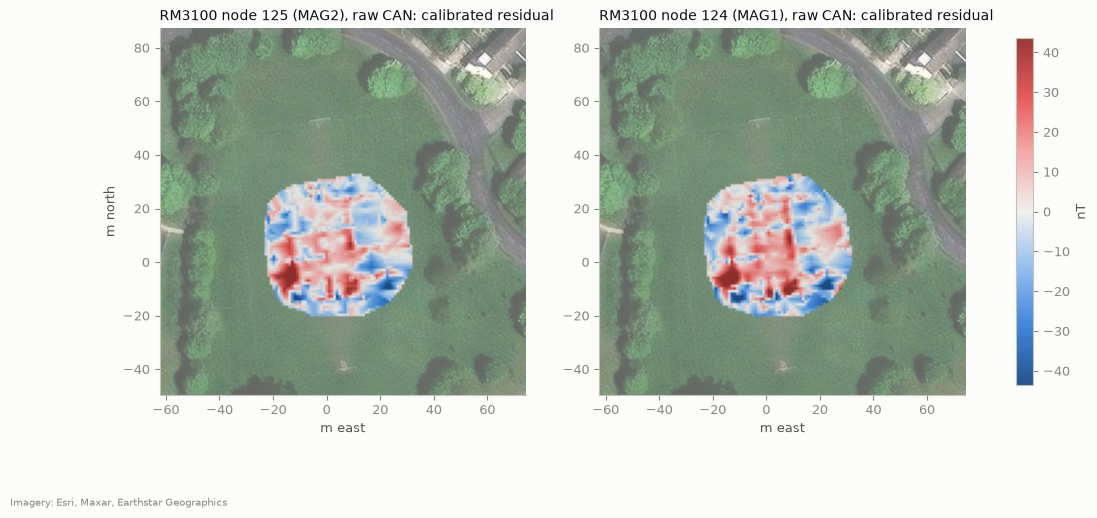

In [9]:
def tile(z, x, y):
    p = TILES / f"{z}_{x}_{y}.jpg"
    if not p.exists():
        TILES.mkdir(parents=True, exist_ok=True)
        try:
            req = urllib.request.Request(f"https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
                                         headers={"User-Agent": "cohera-notebook/1.0"})
            p.write_bytes(urllib.request.urlopen(req, timeout=20).read())
        except Exception:
            return None
    return np.asarray(mpimg.imread(p), float) / 255.0

def satellite(pad_m=15, z=19):
    sv = (GPS[:, 0] > PHASES["survey"][0]) & (GPS[:, 0] < PHASES["survey"][1])
    lon_min, lon_max = GPS[sv, 3].min() - pad_m / M_LON, GPS[sv, 3].max() + pad_m / M_LON
    lat_min, lat_max = GPS[sv, 2].min() - pad_m / M_LAT, GPS[sv, 2].max() + pad_m / M_LAT
    sc = 256 * 2 ** z
    px = lambda lon, lat: ((lon + 180) / 360 * sc, (0.5 - math.log((1 + math.sin(math.radians(lat))) / (1 - math.sin(math.radians(lat)))) / (4 * math.pi)) * sc)
    x0, y1 = px(lon_min, lat_min); x1, y0 = px(lon_max, lat_max)
    tx0, tx1, ty0, ty1 = int(x0 // 256), int(x1 // 256), int(y0 // 256), int(y1 // 256)
    mos = np.zeros(((ty1 - ty0 + 1) * 256, (tx1 - tx0 + 1) * 256, 3))
    for ty in range(ty0, ty1 + 1):
        for tx in range(tx0, tx1 + 1):
            im = tile(z, tx, ty)
            if im is not None:
                mos[(ty - ty0) * 256:(ty - ty0 + 1) * 256, (tx - tx0) * 256:(tx - tx0 + 1) * 256] = im[:, :, :3]
    ll = lambda X, Y: (X / sc * 360 - 180, math.degrees(math.atan(math.sinh(math.pi * (1 - 2 * Y / sc)))))
    w, n = ll(tx0 * 256, ty0 * 256); e, s = ll((tx1 + 1) * 256, (ty1 + 1) * 256)
    return mos, ((w - LON0) * M_LON, (e - LON0) * M_LON, (s - LAT0) * M_LAT, (n - LAT0) * M_LAT)

IMG, EXT = satellite()
SM, TESTS = {}, {}
for k in ("n125", "n124"):
    o, c = FS[k], COMP[k]; ok = np.isfinite(c["r"])
    sm = np.full(len(o["t"]), np.nan); sm[ok] = median_filter(c["r"][ok], size=int(c["hz"] / 2) | 1, mode="nearest")
    sm[~o["straight"]] = np.nan; SM[k] = sm
LIM = np.nanpercentile(np.abs(np.r_[SM["n125"], SM["n124"]]), 97)
fig, ax = plt.subplots(1, 2, figsize=(13, 6))
g = np.arange(-35, 36, 1.0)
for a, k in zip(ax, ("n125", "n124")):
    o = FS[k]; ok = np.isfinite(SM[k])
    G = griddata((o["e"][ok], o["n"][ok]), SM[k][ok], tuple(np.meshgrid(g, g)), method="linear")
    a.imshow(IMG, extent=EXT, alpha=0.6); a.grid(False)
    im = a.imshow(G, extent=(g[0], g[-1], g[0], g[-1]), origin="lower", cmap=DIVERGING, vmin=-LIM, vmax=LIM, alpha=0.9)
    a.set_xlim(EXT[0], EXT[1]); a.set_ylim(EXT[2], EXT[3]); a.set_aspect("equal")
    a.set_title(f"{SENSORS[k]['label']}: calibrated residual", color=INK); a.set_xlabel("m east")
ax[0].set_ylabel("m north"); fig.colorbar(im, ax=ax, shrink=0.75, label="nT")
fig.text(0.01, 0.005, "Imagery: Esri, Maxar, Earthstar Geographics", fontsize=7, color=MUTED)

CELL = 4.0
def cm(o, v, sel):
    kk = np.floor(o["e"][sel] / CELL).astype(int) * 1000 + np.floor(o["n"][sel] / CELL).astype(int)
    return {q: (v[sel][kk == q].mean(), (kk == q).sum()) for q in np.unique(kk)}
for k in ("n125", "n124"):
    o, v = FS[k], SM[k]; ok = np.isfinite(v); rel = (o["yaw"] + 10) % 360
    ns = ok & ((rel > 330) | (rel < 30) | ((rel > 150) & (rel < 210)))
    ew = ok & (((rel > 60) & (rel < 120)) | ((rel > 240) & (rel < 300)))
    A, B = cm(o, v, ns), cm(o, v, ew)
    keys = [q for q in set(A) & set(B) if A[q][1] >= 3 and B[q][1] >= 3]
    x = np.array([A[q][0] for q in keys]); y = np.array([B[q][0] for q in keys])
    TESTS[k] = (np.corrcoef(x, y)[0, 1] if len(x) > 5 else np.nan, len(x), np.std(x - y) / np.sqrt(2) if len(x) else np.nan)
    print(f"{SENSORS[k]['label']}: N-S vs E-W lines over the same ground: r = {TESTS[k][0]:+.2f} over {TESTS[k][1]} cells, "
          f"per-cell noise {TESTS[k][2]:.0f} nT")

## 7. Headline numbers (live)

In [10]:
c5, c4, c0 = COMP["n125"], COMP["n124"], COMP["puck"]
HEAD = pd.DataFrame([
    ("Raw CAN logging", f"works: 25 Hz instead of 10 Hz, ~12-24 nT steps instead of 100 nT"),
    ("Calibrate on spins, fly the survey", f"node 125: {c5['raw']:.0f} -> {c5['spin']:.0f} nT; node 124: {c4['raw']:.0f} -> {c4['spin']:.0f} nT"),
    ("Best calibration (survey 2-fold)", f"node 125: {c5['cv']:.0f} nT; node 124: {c4['cv']:.0f} nT; GPS puck {c0['cv']:.0f} nT"),
    ("Last night, V2 boom, MAG log", "outer 36 nT, inner 64 nT, puck 454 nT"),
    ("Fast noise (> 0.5 Hz), calibrated", f"node 125: {c5['fast']:.0f} nT, node 124: {c4['fast']:.0f} nT (last night 32 / 41, floor then 29)"),
    ("Ground signal at 10 m", f"crossing lines r = {TESTS['n125'][0]:+.2f} (node 125), per-cell noise {TESTS['n125'][2]:.0f} nT"),
], columns=["item", "result"]).set_index("item")
pd.set_option("display.max_colwidth", 200); HEAD

,result
item,
Raw CAN logging,"works: 25 Hz instead of 10 Hz, ~12-24 nT steps instead of 100 nT"
"Calibrate on spins, fly the survey",node 125: 278 -> 31 nT; node 124: 513 -> 40 nT
Best calibration (survey 2-fold),node 125: 22 nT; node 124: 24 nT; GPS puck 462 nT
"Last night, V2 boom, MAG log","outer 36 nT, inner 64 nT, puck 454 nT"
"Fast noise (> 0.5 Hz), calibrated","node 125: 15 nT, node 124: 15 nT (last night 32 / 41, floor then 29)"
Ground signal at 10 m,"crossing lines r = -0.18 (node 125), per-cell noise 15 nT"
